# 01 — Dataset Exploration

Explore the Monet paintings and photo JPG datasets after the dataset sanity check.

In [1]:
# standard library
from pathlib import Path
import random
import sys

# third-party
import matplotlib.pyplot as plt
from PIL import Image

# local
project_root = Path.cwd()
if not (project_root / "scripts").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "scripts"))

from painter_dataset_helpers import build_dataset_overview, load_datasets


Matplotlib is building the font cache; this may take a moment.


In [ ]:
datasets = load_datasets()
overview = build_dataset_overview(datasets)
for name, details in overview.items():
    print(f"{name}: {details['file_count']:,} files — {details['path']}")


monet_jpg: 300 files — /Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/monet_jpg
photo_jpg: 7,038 files — /Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/photo_jpg
monet_tfrec: 5 files — /Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/monet_tfrec
photo_tfrec: 20 files — /Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/photo_tfrec


In [3]:
overview

{'monet_jpg': {'path': PosixPath('/Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/monet_jpg'),
  'file_count': 300},
 'photo_jpg': {'path': PosixPath('/Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/photo_jpg'),
  'file_count': 7038},
 'monet_tfrec': {'path': PosixPath('/Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/monet_tfrec'),
  'file_count': 5},
 'photo_tfrec': {'path': PosixPath('/Users/KurtMeehanPro/Documents/code/git/painter-myself/data/raw/photo_tfrec'),
  'file_count': 20}}

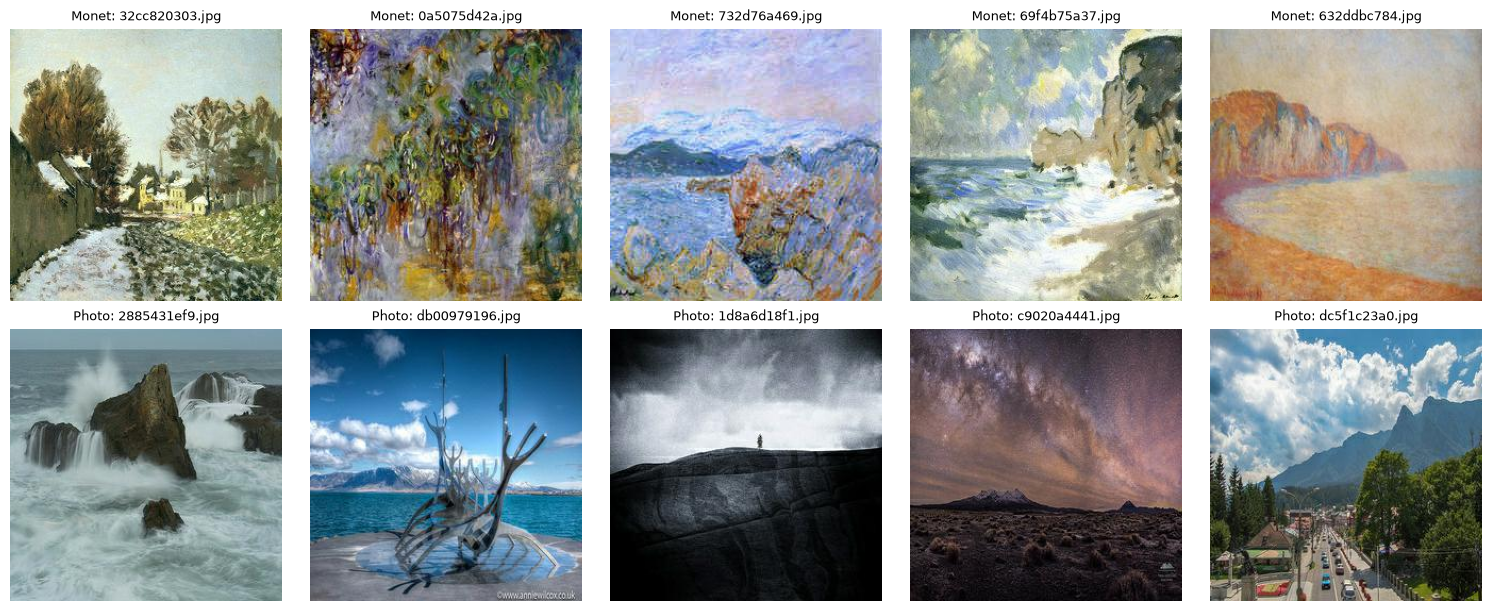

In [4]:
rng = random.Random(42)
fig, axes = plt.subplots(2, 5, figsize=(15, 6), layout="constrained")

for row, (name, label) in enumerate((("monet_jpg", "Monet"), ("photo_jpg", "Photo"))):
    image_paths = sorted(datasets[name].glob("*.jpg"))
    samples = rng.sample(image_paths, 5)
    for ax, image_path in zip(axes[row], samples):
        with Image.open(image_path) as image:
            ax.imshow(image)
        ax.set_title(f"{label}: {image_path.name}", fontsize=9)
        ax.axis("off")

plt.show()


## JPG properties and dimensions

Inspect the first filename-sorted JPG in each collection for pixel properties, then check image dimensions across every JPG. Pixel ranges below describe these two examples.


In [5]:
# third-party
import numpy as np

for name in ("monet_jpg", "photo_jpg"):
    image_path = sorted(datasets[name].glob("*.jpg"))[0]
    with Image.open(image_path) as image:
        width, height = image.size
        channels = len(image.getbands())
        pixels = np.asarray(image)
        print(f"{name} — {image_path.name}: width={width}, height={height}, "
              f"channels={channels}, dtype={pixels.dtype}, "
              f"min={pixels.min()}, max={pixels.max()}")


monet_jpg — 000c1e3bff.jpg: width=256, height=256, channels=3, dtype=uint8, min=0, max=255
photo_jpg — 00068bc07f.jpg: width=256, height=256, channels=3, dtype=uint8, min=0, max=255


In [7]:
# standard library
from collections import Counter

for name in ("monet_jpg", "photo_jpg"):
    dimension_counts = Counter()
    channel_counts = Counter()
    for image_path in sorted(datasets[name].glob("*.jpg")):
        with Image.open(image_path) as image:
            dimension_counts[image.size] += 1
            channel_counts[len(image.getbands())] += 1
    print(f"{name}: {sum(dimension_counts.values()):,} JPGs; "
          f"consistent dimensions: {len(dimension_counts) == 1}")
    for (width, height), count in sorted(dimension_counts.items()):
        print(f"  {width} × {height}: {count:,} images")
    print(f"  Consistent channel count: {len(channel_counts) == 1}")
    for channels, count in sorted(channel_counts.items()):
        print(f"  {channels} channels: {count:,} images")


monet_jpg: 300 JPGs; consistent dimensions: True
  256 × 256: 300 images
  Consistent channel count: True
  3 channels: 300 images
photo_jpg: 7,038 JPGs; consistent dimensions: True
  256 × 256: 7,038 images
  Consistent channel count: True
  3 channels: 7,038 images
